# Lab 5: Frameworks and automatic differentiation
Run all cells. The script performs all experiments and saves evidence next to the notebook. See README.md for methodology.

In [ ]:
"""Lab 5. Run: python lab05.py (writes results.json and training.png beside this file)."""
import json
import math
import platform
import statistics
import time
from pathlib import Path

import numpy as np
import torch
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split


class Value:
    def __init__(self, data, parents=(), op=''):
        self.data = float(data)
        self.grad = 0.0
        self.parents = tuple(parents)
        self.op = op
        self._backward = lambda: None

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), '+')
        def backward():
            self.grad += out.grad
            other.grad += out.grad
        out._backward = backward
        return out
    __radd__ = __add__

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), '*')
        def backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
        out._backward = backward
        return out
    __rmul__ = __mul__

    def __pow__(self, power):
        if not isinstance(power, (int, float)):
            raise TypeError('Only constant numeric powers are supported')
        out = Value(self.data ** power, (self,), '**')
        def backward():
            self.grad += (0.0 if power == 0 else power * self.data ** (power-1)) * out.grad
        out._backward = backward
        return out

    def __neg__(self): return self * -1
    def __sub__(self, other): return self + (-other)
    def __rsub__(self, other): return other + (-self)
    def __truediv__(self, other): return self * (other ** -1)

    def relu(self):
        out = Value(max(0, self.data), (self,), 'relu')
        def backward(): self.grad += (self.data > 0) * out.grad
        out._backward = backward
        return out

    def sigmoid(self):
        z = math.exp(-abs(self.data))
        s = 1/(1+z) if self.data >= 0 else z/(1+z)
        out = Value(s, (self,), 'sigmoid')
        def backward(): self.grad += s * (1-s) * out.grad
        out._backward = backward
        return out

    def softplus(self):
        out = Value(max(self.data, 0) + math.log1p(math.exp(-abs(self.data))), (self,), 'softplus')
        def backward():
            z = math.exp(-abs(self.data))
            self.grad += (1/(1+z) if self.data >= 0 else z/(1+z)) * out.grad
        out._backward = backward
        return out

    def sum(self): return self  # A scalar is already its own sum.

    def backward(self):
        # Iterative postorder traversal avoids Python recursion depth limits.
        topo, seen, stack = [], set(), [(self, False)]
        while stack:
            node, expanded = stack.pop()
            if expanded:
                topo.append(node)
            elif node not in seen:
                seen.add(node)
                stack.append((node, True))
                stack.extend((p, False) for p in node.parents if p not in seen)
        # Each call computes fresh gradients; branches accumulate within the call.
        for node in topo: node.grad = 0.0
        self.grad = 1.0
        for node in reversed(topo): node._backward()


def check_gradients():
    cases = [(1.2, -.7, .3), (0., 2., -.4), (-1.3, -.8, .6)]
    rows = []
    for case in cases:
        a,b,c = [Value(x) for x in case]
        out = ((a*b+c)**2).relu().sum()
        out.backward()
        t = [torch.tensor(x, dtype=torch.float64, requires_grad=True) for x in case]
        ((t[0]*t[1]+t[2])**2).relu().sum().backward()
        exact = np.array([a.grad,b.grad,c.grad])
        ref = np.array([x.grad.item() for x in t])
        def f(v): return max((v[0]*v[1]+v[2])**2, 0)
        numeric = []
        for j in range(3):
            plus, minus = list(case), list(case)
            plus[j] += 1e-6; minus[j] -= 1e-6
            numeric.append((f(plus)-f(minus))/2e-6)
        row = dict(inputs=case, custom=exact.tolist(), torch=ref.tolist(), numerical=numeric,
                   torch_error=float(max(abs(exact-ref))), numerical_error=float(max(abs(exact-numeric))))
        assert row['torch_error'] < 1e-6 and row['numerical_error'] < 1e-6
        rows.append(row)
    x = Value(3); y = x*x+x; y.backward(); assert x.grad == 7
    y.backward(); assert x.grad == 7
    x = Value(-2); x.relu().backward(); assert x.grad == 0
    return rows


def initial(seed):
    r = np.random.default_rng(seed)
    return [r.normal(0, .6, (8,2)), np.zeros(8), r.normal(0, .6, (1,8)), np.zeros(1)]


def train_custom(arrays, X, y, Xt, yt, epochs, lr):
    w1,b1,w2,b2 = [[[Value(v) for v in row] for row in arrays[0]],
                    [Value(v) for v in arrays[1]], [Value(v) for v in arrays[2][0]], Value(arrays[3][0])]
    params = [v for row in w1 for v in row]+b1+w2+[b2]
    def forward(row):
        h = [(sum(w*float(x) for w,x in zip(ws,row))+b).relu() for ws,b in zip(w1,b1)]
        return sum(w*x for w,x in zip(w2,h))+b2
    losses=[]
    start=time.perf_counter()
    for _ in range(epochs):
        logits=[forward(row) for row in X]
        # BCE(sigmoid(z), y) = softplus(z)-y*z, evaluated stably.
        loss=sum(z.softplus()-float(target)*z for z,target in zip(logits,y))/len(y)
        loss.backward()
        for p in params: p.data -= lr*p.grad
        losses.append(loss.data)
    elapsed=time.perf_counter()-start
    pred=np.array([forward(row).sigmoid().data for row in Xt])
    return elapsed, losses, float(np.mean((pred>=.5)==yt))


def make_model(arrays):
    model=torch.nn.Sequential(torch.nn.Linear(2,8),torch.nn.ReLU(),torch.nn.Linear(8,1)).double()
    with torch.no_grad():
        for p,a in zip(model.parameters(),arrays): p.copy_(torch.tensor(a))
    return model


def train_torch(arrays,X,y,Xt,yt,epochs,lr):
    model=make_model(arrays)
    x=torch.tensor(X); target=torch.tensor(y[:,None],dtype=torch.float64)
    opt=torch.optim.SGD(model.parameters(),lr=lr)
    losses=[]
    start=time.perf_counter()
    for _ in range(epochs):
        opt.zero_grad(set_to_none=True)
        loss=torch.nn.functional.binary_cross_entropy_with_logits(model(x),target)
        loss.backward(); opt.step(); losses.append(loss.item())
    elapsed=time.perf_counter()-start
    with torch.no_grad(): pred=model(torch.tensor(Xt)).sigmoid().numpy().ravel()
    return elapsed,losses,float(np.mean((pred>=.5)==yt)),model


def benchmark(fn, iterations=500, repeats=5):
    for _ in range(30): fn()
    samples=[]
    for _ in range(repeats):
        start=time.perf_counter()
        for _ in range(iterations): fn()
        samples.append((time.perf_counter()-start)/iterations*1e6)
    return dict(samples_us=samples,median_us=statistics.median(samples))


def main():
    torch.set_num_threads(1); torch.manual_seed(42)
    root=Path.cwd()
    result=dict(environment=dict(python=platform.python_version(),torch=torch.__version__,numpy=np.__version__,
                                 platform=platform.platform(),device='CPU',threads=1),gradients=check_gradients())
    X,y=make_moons(n_samples=200,noise=.15,random_state=42)
    X,Xt,y,yt=train_test_split(X,y,test_size=.25,random_state=42,stratify=y)
    epochs,lr=300,.1
    # Warm up both paths before recording the five full training runs.
    train_custom(initial(42),X[:10],y[:10],Xt,yt,2,lr)
    train_torch(initial(42),X[:10],y[:10],Xt,yt,2,lr)
    custom=[]; pytorch=[]
    for run in range(5):
        print('Training run',run+1,flush=True)
        a=initial(42)  # Identical initial weights, data, precision and SGD updates.
        tc,lc,ac=train_custom(a,X,y,Xt,yt,epochs,lr)
        tp,lp,ap,model=train_torch(a,X,y,Xt,yt,epochs,lr)
        custom.append(tc); pytorch.append(tp)
    result['training']=dict(samples=200,train=150,test=50,epochs=epochs,lr=lr,batch_size=150,
        custom_seconds=custom,torch_seconds=pytorch,custom_median=statistics.median(custom),
        torch_median=statistics.median(pytorch),custom_accuracy=ac,torch_accuracy=ap,
        custom_final_loss=lc[-1],torch_final_loss=lp[-1],max_loss_difference=float(np.max(np.abs(np.array(lc)-lp))))
    assert result['training']['max_loss_difference'] < 1e-10
    sample=torch.tensor(X)
    model.eval()
    start=time.perf_counter(); traced=torch.jit.trace(model,sample); trace_seconds=time.perf_counter()-start
    with torch.no_grad():
        error=(model(sample)-traced(sample)).abs().max().item()
        eager=benchmark(lambda:model(sample)); trace=benchmark(lambda:traced(sample))
        base=torch.randn(512,512,dtype=torch.float64)
        view=base.t(); contiguous=view.contiguous()
        # Same logical values and shape; allocation of the copy is measured separately.
        weight=torch.randn(512,512,dtype=torch.float64)
        noncontig=benchmark(lambda:torch.mm(view,weight),iterations=30)
        contig=benchmark(lambda:torch.mm(contiguous,weight),iterations=30)
        copy=benchmark(lambda:view.contiguous(),iterations=100)
    result['execution']=dict(method='torch.jit.trace',trace_seconds=trace_seconds,max_output_error=error,
                              eager=eager,traced=trace)
    assert error < 1e-12
    out=model(sample)
    graph=[]; pending=[out.grad_fn]; visited=set()
    while pending:
        node=pending.pop()
        if node is None or node in visited: continue
        visited.add(node); graph.append(type(node).__name__)
        pending.extend(n for n,_ in node.next_functions)
    result['autograd_nodes']=graph
    (root/'traced_graph.txt').write_text(str(traced.inlined_graph),encoding='utf-8')
    result['tensors']=dict(shape=list(view.shape),dtype=str(view.dtype),view_stride=list(view.stride()),
        contiguous_stride=list(contiguous.stride()),view_is_contiguous=view.is_contiguous(),
        copy_is_contiguous=contiguous.is_contiguous(),equal=torch.equal(view,contiguous),
        noncontiguous_mm=noncontig,contiguous_mm=contig,copy=copy)
    (root/'results.json').write_text(json.dumps(result,indent=2),encoding='utf-8')
    import matplotlib
    matplotlib.use('Agg')
    import matplotlib.pyplot as plt
    fig,ax=plt.subplots(figsize=(7,4)); ax.plot(lc,label='Scalar engine'); ax.plot(lp,'--',label='PyTorch')
    ax.set(xlabel='Epoch',ylabel='BCE loss',title='make_moons: 2 - 8 - 1, full-batch SGD'); ax.legend()
    fig.tight_layout(); fig.savefig(root/'training.png',dpi=160); plt.close(fig)
    print(json.dumps(result,indent=2))


if __name__=='__main__': main()


# Звіт: Lab 5 — Frameworks and automatic differentiation

Дата виконання: 4 листопада 2026 року.

## 1–3. Власний autograd

Реалізовано клас Value: data, grad, parents та локальне правило _backward. Операції +, *, ** і ReLU створюють граф під час forward. Backward виконує ітеративне топологічне сортування, задає градієнт виходу 1 та обходить граф у зворотному порядку. Усі локальні внески додаються через +=. Перед новим backward градієнти обнуляються. Перевірено спільний вузол x*x+x (при x=3 градієнт 7), повторний backward і ReLU на від'ємному вході.

## 4. Перевірка градієнтів

Вираз: `((a*b+c)**2).relu().sum()`. Використано float64, три набори входів та центральну різницю з кроком 1e-6.

Максимальна абсолютна похибка проти PyTorch: **0.000e+00**.

Максимальна абсолютна похибка проти чисельного градієнта: **4.202e-10**.

Обидва результати менші за 1e-6. Докладні градієнти для a, b, c наведено в results.json.

## 5. Навчання make_moons

Архітектура 2→8→1: Linear, ReLU, Linear, sigmoid; BCE. Для стійкості обчислюється еквівалентний BCE з логітів. Дані: 200 точок, noise=0.15, seed=42, розбиття 150/50 зі stratify. 300 епох, full-batch SGD, lr=0.1, float64, CPU. Однакові початкові ваги в обох реалізаціях; попередній прогрів не входить у час. У час входить увесь навчальний цикл, без створення моделі й оцінювання.

| Запуск | Власний рушій, с | PyTorch, с |
|---|---:|---:|
| 1 | 115.209244 | 0.492715 |
| 2 | 111.963950 | 0.503227 |
| 3 | 86.639719 | 0.184864 |
| 4 | 59.110257 | 0.124862 |
| 5 | 56.757831 | 0.140315 |
| Медіана | 86.639719 | 0.184864 |

PyTorch швидший у **468.67 раза** за відношенням медіан. Це також ефект векторизації: PyTorch обробляє весь пакет тензорами, а Value виконує скалярні Python-операції.

Час помітно зменшується в пізніших запусках для обох реалізацій. Порядок завжди був Value, потім PyTorch; фонове навантаження не контролювалося. Тому відношення медіан є локальним описовим результатом, а не стабільною оцінкою прискорення для інших умов.

Фінальний train BCE: власний **0.31629219**, PyTorch **0.31629219**. Test accuracy: власний **90.0%**, PyTorch **90.0%**. Максимальна різниця loss між реалізаціями за всі епохи: **5.551e-16**. Це один фіксований поділ даних, а не оцінка статистичної невизначеності якості.

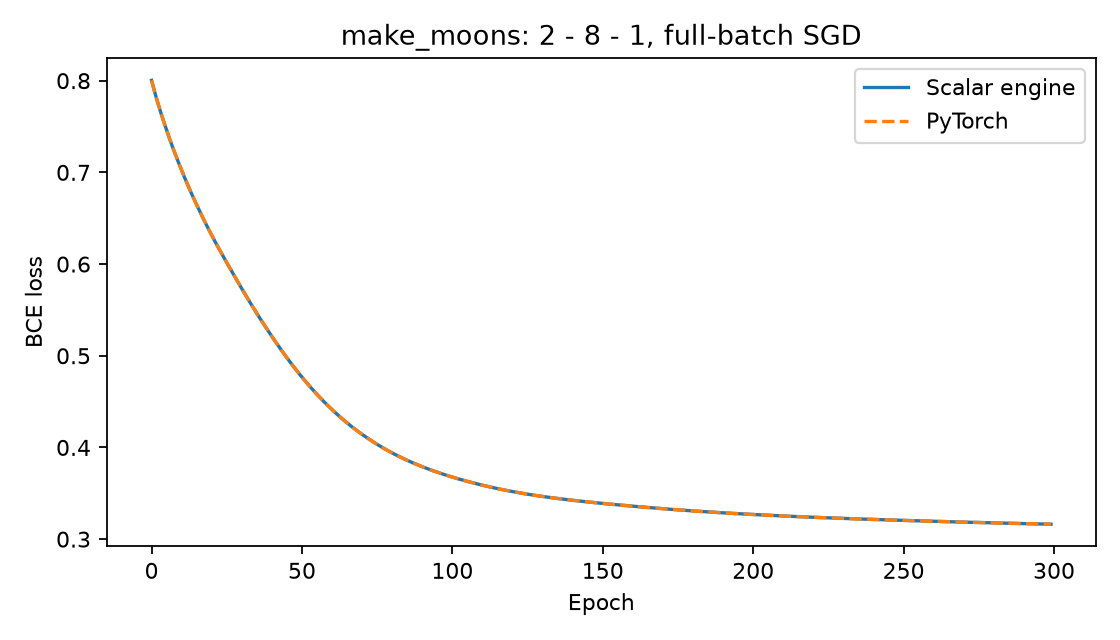

## 6. Графи, режими виконання та тензори

Вузли графа autograd: AddmmBackward0, TBackward0, AccumulateGrad, ReluBackward0, AddmmBackward0, TBackward0, AccumulateGrad, AccumulateGrad, AccumulateGrad. AccumulateGrad відповідає листовим параметрам; AddmmBackward — лінійному шару, ReluBackward — активації. Граф tracing збережено в traced_graph.txt.

Порівняно eager і дозволений методичкою torch.jit.trace. Час побудови trace: **0.099825 с**. Після прогріву 30 викликів виконано п'ять серій по 500 inference-викликів, no_grad, пакет 150×2.

Встановлена версія PyTorch вивела попередження про застарівання torch.jit.trace, але виконання успішне. Метод обрано як прямо дозволену альтернативу з методички.

| Режим | Медіана, мкс/виклик |
|---|---:|
| Eager | 36.607 |
| Traced | 26.757 |

Відношення eager/traced: **1.368**. Максимальна різниця виходів: **0.000e+00**.

За цим вимірюванням підготовка trace окупається приблизно після **10,134 викликів**.

Tracing може зменшити накладні витрати повторних викликів, але його підготовка потребує часу. Найбільший сенс він має для багатьох повторень зі стабільним графом. Для одноразового запуску або обчислень, де домінують великі матричні операції, користь може бути малою. Цей експеримент використовує tracing; прискорення torch.compile не вимірювалося. Trace залежних від даних Python-розгалужень може зафіксувати лише один шлях.

Тест пам'яті: транспонований view і його contiguous-копія мають однакові значення та shape [512, 512], dtype torch.float64. Strides view: [1, 512]; копії: [512, 1]. is_contiguous: view=False, копія=True.

| Операція | Медіана, мкс |
|---|---:|
| Non-contiguous view @ weight | 8987.613 |
| Contiguous copy @ weight | 8809.310 |
| Створення contiguous-копії | 534.744 |

Для множення: прогрів 30 викликів, п'ять серій по 30 операцій. Вартість копіювання виключено з порівняння множень і виміряно окремо (п'ять серій по 100 викликів). Відношення non-contiguous/contiguous: **1.020**. Значення понад 1 означає уповільнення view. Цей результат стосується транспонованої матриці 512×512 та операції mm; він не означає, що всі non-contiguous тензори мають таку саму поведінку. BLAS може ефективно працювати з транспонуванням. Примусове contiguous() додає ціну копіювання, яку потрібно враховувати при виборі оптимізації.

Різниця медіан близько 2% менша за розкид окремих серій. Цей тест не дає переконливих підстав стверджувати систематичне уповільнення через такий view.

## Середовище та відтворюваність

Python 3.11.8; PyTorch 2.15.0+cpu; NumPy 2.4.6; Windows-10-10.0.26200-SP0. CPU, один потік PyTorch. Точні версії залежностей збережено в environment.txt. Сирі вимірювання та перевірки — results.json. Значення часу залежать від комп'ютера та фонового навантаження; це локальні вимірювання без довірчих інтервалів.

Код: lab05.py або lab05.ipynb; інструкція: README.md. Усі шість технічних завдань із наданої методички виконано. Згаданий у листі підручник не надано і не використовувався як прочитане джерело; додаткові усні вимоги викладача не відомі.
